<a href="https://colab.research.google.com/github/SyedSaad74/DAV/blob/main/Lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv(r"Student_Performance.csv")
print(df.head())
print(df.info())
print(df.describe())
print("Missing values:\n", df.isnull().sum())

df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes":1, "No":0})




   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------              

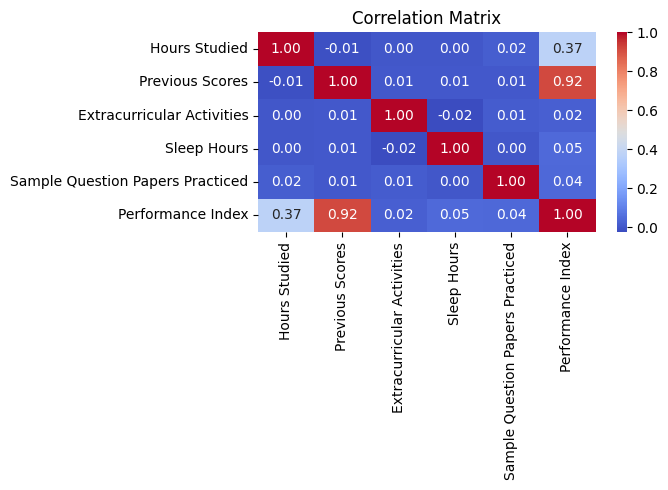


=== Simple Linear Regression ===
Intercept (b0): 41.436634826535744
Slope (b1): 2.784300441170774
R2  : 0.13160425385996788
RMSE : 17.93919001285204


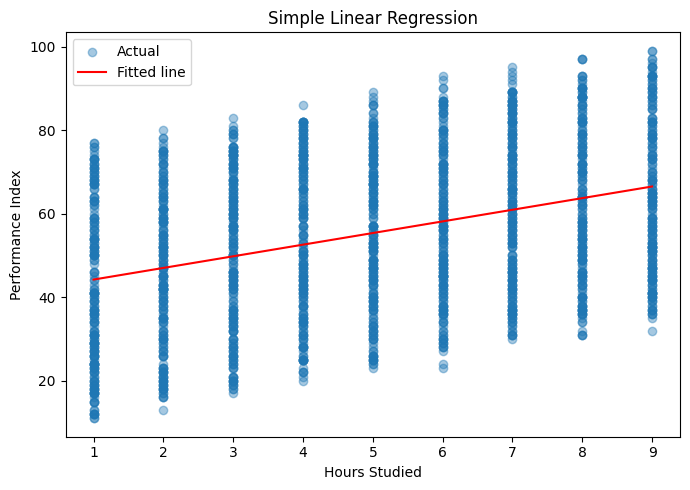

In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()

X_simple = df[["Hours Studied"]]
y = df["Performance Index"]

Xs_simple_train, Xs_test, ys_train, ys_test = train_test_split(X_simple, y, test_size=0.2, random_state=42)

simple_model = LinearRegression()
simple_model.fit(Xs_simple_train, ys_train)

print("\n=== Simple Linear Regression ===")
print("Intercept (b0):", simple_model.intercept_)
print("Slope (b1):", simple_model.coef_[0])

ys_pred = simple_model.predict(Xs_test)
print("R2  :", r2_score(ys_test, ys_pred))
print("RMSE :", np.sqrt(mean_squared_error(ys_test, ys_pred)))

plt.figure(figsize=(7, 5))
plt.scatter(Xs_test, ys_test, alpha=0.4, label="Actual")
plt.plot(Xs_test.sort_values("Hours Studied"),
         simple_model.predict(Xs_test.sort_values("Hours Studied")),
         color="red", label="Fitted line")
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.legend()
plt.title("Simple Linear Regression")
plt.tight_layout()
plt.savefig("02_simple_fit.png")
plt.show()

In [ ]:

X = df.drop(columns=["Performance Index"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

print("\n=== Multiple Linear Regression ===")
print("Intercept:", multi_model.intercept_)
for name, coef in zip(X.columns, multi_model.coef_):
    print(f"{name:35s} {coef: .4f}")
y_pred = multi_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
n, p =X_test.shape
adj_r2 = 1 - (1 - r2) * (n-1) / (n-p-1)

print("R2    :", r2)
print("Adjusted R2 :", adj_r2)
print("RMSE  :", rmse)



=== Multiple Linear Regression ===
Intercept: -33.92194621555638
Hours Studied                        2.8525
Previous Scores                      1.0170
Extracurricular Activities           0.6086
Sleep Hours                          0.4769
Sample Question Papers Practiced     0.1918
R2    : 0.9889832909573145
Adjusted R2 : 0.9889556663107681
RMSE  : 2.0205515085050054



                             OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 1.398e+05
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        04:42:41   Log-Likelihood:                -17063.
No. Observations:                8000   AIC:                         3.414e+04
Df Residuals:                    7994   BIC:                         3.418e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const 

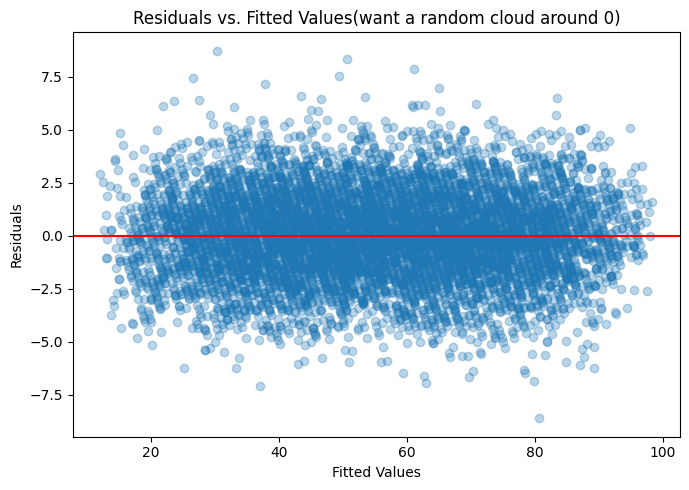

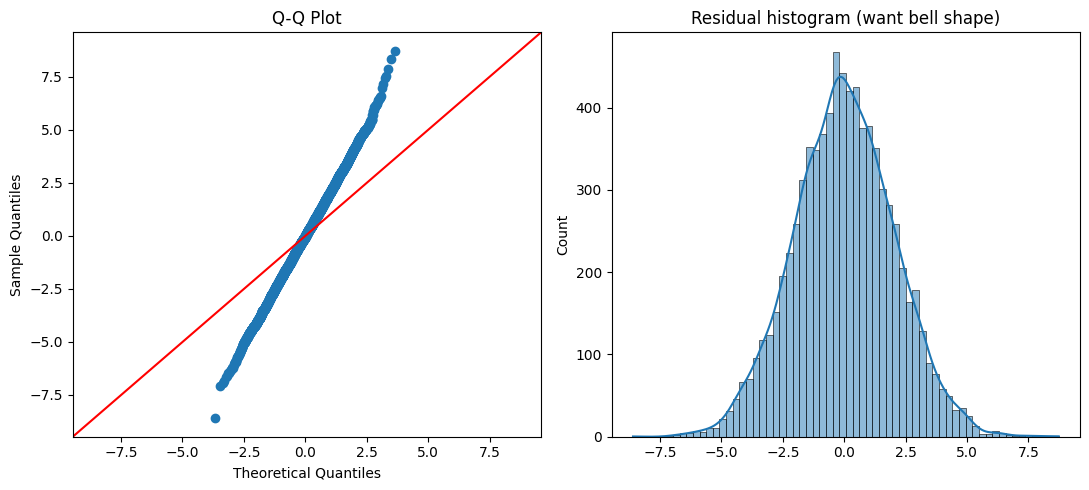

In [ ]:
X_train_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_sm).fit()
print("\n", ols.summary())

fitted = ols.fittedvalues
resid = ols.resid

plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted Values(want a random cloud around 0)")
plt.tight_layout()
plt.savefig("03_resid_vs_fitted.png")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
sm.qqplot(resid, line="45", ax=ax[0])
ax[0].set_title("Q-Q Plot")
sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram (want bell shape)")
plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()

In [ ]:
bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_train_sm)
print("Breusch-Pagan p-value  :", bp_p)

print("Durbin-Watson:", durbin_watson(resid))
vif = pd.DataFrame({
    "VIF": [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])],
    "feature": X_train.columns
})
print("\nVIF:\n", vif)

Breusch-Pagan p-value  : 0.2396245087908097
Durbin-Watson: 2.0331060225040156

VIF:
         VIF                           feature
0  1.000387                     Hours Studied
1  1.000243                   Previous Scores
2  1.000428        Extracurricular Activities
3  1.000461                       Sleep Hours
4  1.000320  Sample Question Papers Practiced


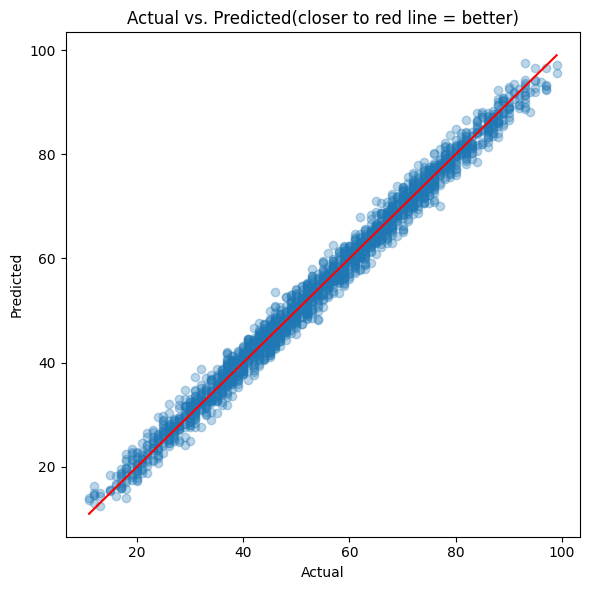

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs. Predicted(closer to red line = better)")
plt.tight_layout()
plt.savefig("05_Actual_vs_pred.png")
plt.show()